## Veri Kümesi Hikayesi ve Amacı
Bu projede, canlı organizmaların temel yapı taşları olan proteinlerin **aminoasit dizilimleri (sequence)** analiz edilerek, proteinin hangi biyolojik aileye (Enzim, Yapısal Protein vb.) ait olduğu tahmin edilmeye çalışılmıştır.

* **Veri Kaynağı:** Kaggle - Protein Data Set (Source: RCSB PDB)
* **Veri Linki:** [https://www.kaggle.com/datasets/shahir/protein-data-set](https://www.kaggle.com/datasets/shahir/protein-data-set)
* **Veri Tipi:** Aminoasit Dizileri (Amino Acid Sequences).

**structureId:** Veri setinin iki farklı dosyasını (pdb_data_no_dups.csv ve pdb_data_seq.csv) birbiriyle eşleştirmek ve birleştirmek (merge) için kullanılan benzersiz protein kimliğidir.

**macromoleculeType:** Veri temizleme aşamasında kullanılmıştır. Analizin sadece proteinler üzerinde yapılması amacıyla, bu sütunu "Protein" olan veriler filtrelenerek diğer molekül türleri (DNA, RNA vb.) elenmiştir.

**classification (Hedef Değişken):** Modelin tahmin etmesi beklenen hedef çıktıdır. Ayrıca veri ön işleme aşamasında, veri setindeki en yaygın 10 sınıfı belirlemek ve filtrelemek için kullanılmıştır.

**sequence (Girdi Verisi):** Modelin eğitiminde kullanılan ana veridir. Proteinlerin aminoasit dizilimlerini içeren bu metin verisi, "K-mer" tekniği (3'lü parçalama) kullanılarak modelin işleyebileceği özniteliklere dönüştürülmüştür.

NOT: veri kümesinde daha birçok özelliklik var ama sadece kullandıklarımı not düştüm.

Kütüphaneler ve Veri Yükleme

In [ ]:
# Gerekli Kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Kaggle'dan indirilen iki dosyayı da okuyoruz.(iki dosya olmassının sebebi kaggle da paylaşan veri kümelerini öyle ayarlamış ve protein dizilimleri için birleştirmem gerekiyordu)

df_meta = pd.read_csv('pdb_data_no_dups.csv')
df_seq = pd.read_csv('pdb_data_seq.csv')

# İki tabloyu 'structureId' üzerinden birleştiriyoruz
data = pd.merge(df_meta, df_seq, on='structureId')

# Sütun isimlerini küçük harfe çevir 
data.columns = [c.lower() for c in data.columns]

# Sadece Proteinleri al
if 'macromoleculetype_x' in data.columns:
     data = data[data['macromoleculetype_x'] == 'Protein']
elif 'macromoleculetype' in data.columns:
     data = data[data['macromoleculetype'] == 'Protein']

print("Veri başarıyla birleştirildi ve yüklendi!")
print(f"Toplam Veri Boyutu: {data.shape}")


Veri başarıyla birleştirildi ve yüklendi!
Toplam Veri Boyutu: (346325, 18)


Veri Ön İşleme

In [2]:
# Eksik verileri temizle
data = data.dropna(subset=['sequence', 'classification'])

# Sınıflandırma için en yaygın 10 protein sınıfını seçelim(daha önce denediğim modeller çok iyi sonuç vermedi.
#Bu yüzden svm kullnmaya karar verdim hem confusion matrix daha düzgün gözüksin hem de veri sayısı düşsğn diye bu kararı aldım)
counts = data['classification'].value_counts()
top_classes = counts.index[:10]

print("Analiz Edilecek Sınıflar:")
print(list(top_classes))

# Sadece bu sınıflara ait verileri alalım
data = data[data['classification'].isin(top_classes)]

data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nModelin Kullanacağı TOPLAM Veri Sayısı: {data.shape[0]}")

Analiz Edilecek Sınıflar:
['HYDROLASE', 'TRANSFERASE', 'OXIDOREDUCTASE', 'IMMUNE SYSTEM', 'LYASE', 'HYDROLASE/HYDROLASE INHIBITOR', 'TRANSCRIPTION', 'VIRAL PROTEIN', 'TRANSPORT PROTEIN', 'VIRUS']

Modelin Kullanacağı TOPLAM Veri Sayısı: 188353


Özellik Çıkarımı

In [3]:
# Protein dizilimlerini makine öğrenmesi modeline anlamlı bir paremetre verebilmek için parçalara ayırıyoruz.
# bunun için "K-mer" tekniği kullandım. Proteinler için 3'lü (Tri-peptide) yapılara yani anlamlı parçalara bçlümler.

def get_kmers(sequence, size=3):
    # 3 harfli parçalara bölme işlemi
    return [sequence[x:x+size].upper() for x in range(len(sequence) - size + 1)]

# Fonksiyonu tüm veri setindeki 'sequence' sütununa uyguluyoruz
data['kmers'] = data['sequence'].apply(lambda x: get_kmers(x))


data_texts = list(data['kmers'])
for item in range(len(data_texts)):
    data_texts[item] = ' '.join(data_texts[item])

# Hedef değişken (Sınıflar) ayrılıyor
y = data['classification'].values

#dçnüşüm sonucu neye benzediğini görmek için bir örnek yazdım
print("K-mer dönüşümü tamamlandı. Örnek bir veri:")
print(data_texts[0][:50] + "...")

K-mer dönüşümü tamamlandı. Örnek bir veri:
AAL ALK LKD KDQ DQL QLI LIH IHN HNL NLL LLK LKE KE...


Veri Keşfi Analizi

C:\Users\teknogenetik\AppData\Local\Temp\ipykernel_3432\952034390.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='classification', data=data,


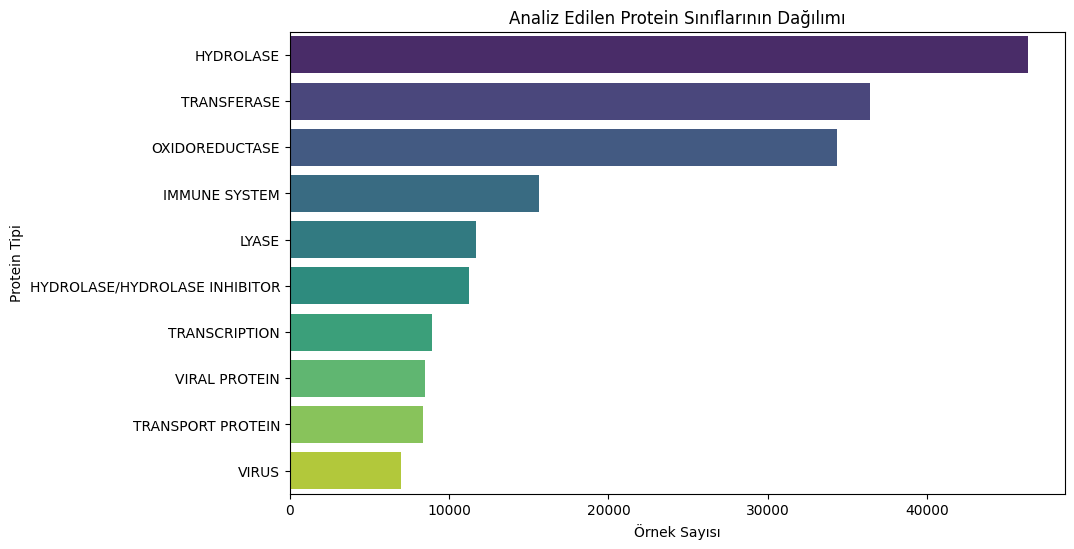

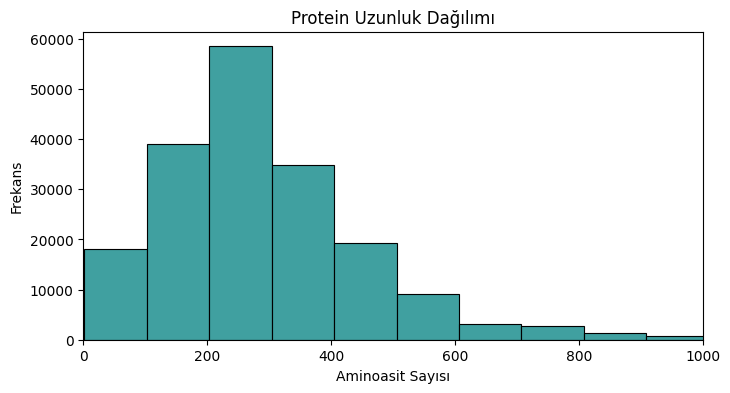

In [ ]:
# Hangi protein türünden kaç adet olduğunu gösteren ve grafikte karşılaştırmamızı sağlayalım
plt.figure(figsize=(10, 6))
sns.countplot(y='classification', data=data, 
              order=data['classification'].value_counts().index, 
              palette='viridis')
plt.title('Analiz Edilen Protein Sınıflarının Dağılımı')
plt.xlabel('Örnek Sayısı')
plt.ylabel('Protein Tipi')
plt.show()

# Veri setindeki proteinlerin aminoasit uzunluklarının histogramı.
data['seq_len'] = data['sequence'].apply(len)
plt.figure(figsize=(8, 4))
sns.histplot(data['seq_len'], bins=50, color='teal')
plt.title('Protein Uzunluk Dağılımı')
plt.xlim(0, 1000) # Okunabilirlik için çok uzun proteinleri göstermedim grafik çok küçük oluyordu.
plt.xlabel('Aminoasit Sayısı')
plt.ylabel('Frekans')
plt.show()

Makine Öğrenmesi Modeli

In [6]:
# Metin verisini sayısal verilere dönüştürme (vektörleştirme)
cv = CountVectorizer(max_features=5000) 
X = cv.fit_transform(data_texts)

# TF-IDF ile önemsiz tekrarları baskılıyoruz
tfidf = TfidfTransformer()
X = tfidf.fit_transform(X)

# Eğitim ve Test Ayrımı
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Eğitim Verisi: {X_train.shape}")
print(f"Test Verisi: {X_test.shape}")

# Model Eğitimi (Linear SVM)
print("Model eğitiliyor")
model = LinearSVC(dual='auto', random_state=42)
model.fit(X_train, y_train)
#uzun sürdüğü için kendime not düştüm
print("Eğitim tamamlandı")

Eğitim Verisi: (150682, 5000)
Test Verisi: (37671, 5000)
Model eğitiliyor
Eğitim tamamlandı


Sonuçlar ve Değerlendirme

--- Model Doğruluğu (Accuracy): %85.47 ---

Sınıflandırma Raporu:
                               precision    recall  f1-score   support

                    HYDROLASE       0.82      0.82      0.82      9290
HYDROLASE/HYDROLASE INHIBITOR       0.76      0.74      0.75      2274
                IMMUNE SYSTEM       0.91      0.93      0.92      3157
                        LYASE       0.91      0.87      0.89      2276
               OXIDOREDUCTASE       0.87      0.91      0.89      6785
                TRANSCRIPTION       0.83      0.81      0.82      1795
                  TRANSFERASE       0.84      0.84      0.84      7299
            TRANSPORT PROTEIN       0.88      0.82      0.85      1649
                VIRAL PROTEIN       0.90      0.85      0.87      1730
                        VIRUS       0.96      0.97      0.96      1416

                     accuracy                           0.85     37671
                    macro avg       0.87      0.86      0.86     37671
         

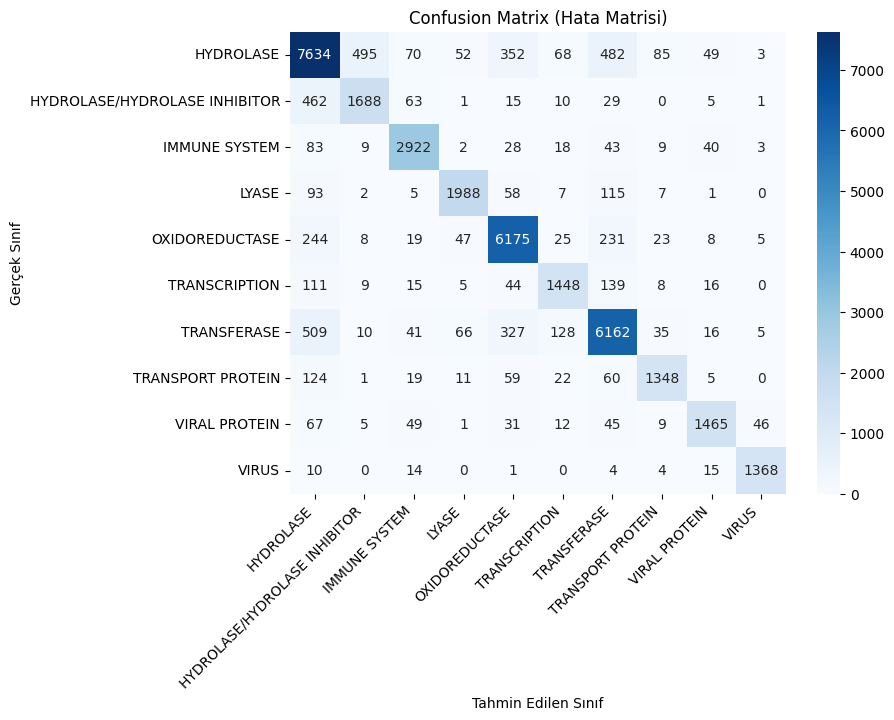

In [7]:

y_pred = model.predict(X_test)

# Doğruluk (Accuracy) Hesaplama
acc = accuracy_score(y_test, y_pred)
print(f"--- Model Doğruluğu (Accuracy): %{acc*100:.2f} ---")

# Sınıflandırma Raporu (Precision, Recall, F1-Score)
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

# Karmaşıklık Matrisi (Confusion Matrix) Görselleştirmesi
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
labels = sorted(list(set(y)))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix (Hata Matrisi)')
plt.ylabel('Gerçek Sınıf')
plt.xlabel('Tahmin Edilen Sınıf')
plt.xticks(rotation=45, ha='right')
plt.show()